# 4. Regression: bike rentals

Two parts with two different goals.

1. **Explain** daily rentals with an ordinary least squares model in statsmodels. Here I care about coefficients, confidence intervals and whether the assumptions hold.
2. **Predict** hourly rentals out of sample. Here I care about error on future data, so I compare a baseline, ridge, lasso and a gradient boosted tree ensemble with time-aware validation.

In [1]:
import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson

from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Lasso, Ridge
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from lightgbm import LGBMRegressor

from src import SEED
from src.data import load_bike_day, load_bike_hour
from src.modeling import chronological_split, regression_metrics, vif_table
from src.plotting import INK_2, PALETTE, save, set_style

set_style()
np.random.seed(SEED)
RESULTS = Path.cwd().parent / "results"
RESULTS.mkdir(exist_ok=True)

day = load_bike_day()

## Part 1. Explaining daily rentals with OLS

### Multicollinearity first

Notebook 1 showed temperature and feels-like temperature move together. The variance inflation factor measures how much a coefficient's variance is inflated because other predictors can explain that column. Above about 5 to 10 is a problem.

In [2]:
cand = day[["temp_c", "feels_like_c", "humidity", "windspeed", "yr", "workingday", "holiday"]]
vif_table(cand)

,feature,vif
0,feels_like_c,63.708182
1,temp_c,63.046057
2,windspeed,1.128132
3,humidity,1.095816
4,workingday,1.071224
5,holiday,1.070061
6,yr,1.017543


In [3]:
vif_table(cand.drop(columns="feels_like_c"))

,feature,vif
0,humidity,1.091456
1,windspeed,1.085817
2,workingday,1.071065
3,holiday,1.068805
4,temp_c,1.040456
5,yr,1.017540


With both temperatures in, their VIFs are enormous and their individual coefficients would be meaningless. Dropping `feels_like_c` brings everything close to 1. I keep `temp_c` because it is the measured value.

### The model

Rentals rise with temperature but drop off when it gets very hot, so I include a squared term. Temperature is centred at 20 C first so the linear coefficient reads as "the slope at 20 C" and is not tangled up with the squared term. Weather and season enter as categories, with clear weather and winter as the reference levels.

In [4]:
day["temp_c20"] = day["temp_c"] - 20
formula = ("cnt ~ temp_c20 + I(temp_c20**2) + humidity + windspeed + yr + workingday + holiday"
           " + C(weather, Treatment('clear')) + C(season_name, Treatment('winter'))")
ols = smf.ols(formula, data=day).fit()
print(ols.summary().tables[0])

                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.851
Model:                            OLS   Adj. R-squared:                  0.849
Method:                 Least Squares   F-statistic:                     342.6
Date:                Wed, 04 Nov 2026   Prob (F-statistic):          1.62e-287
Time:                        15:17:54   Log-Likelihood:                -5873.1
No. Observations:                 731   AIC:                         1.177e+04
Df Residuals:                     718   BIC:                         1.183e+04
Df Model:                          12                                         
Covariance Type:            nonrobust                                         


In [5]:
coef = pd.DataFrame({"coef": ols.params, "ci_low": ols.conf_int()[0], "ci_high": ols.conf_int()[1], "p": ols.pvalues})
coef.index = (coef.index.str.replace("C(weather, Treatment('clear'))", "weather", regex=False)
                        .str.replace("C(season_name, Treatment('winter'))", "season", regex=False))
coef.round(3)

,coef,ci_low,ci_high,p
Intercept,5107.304,4644.925,5569.682,0.000
weather[T.light rain/snow],-1912.319,-2285.185,-1539.453,0.000
weather[T.mist],-424.129,-570.244,-278.014,0.000
season[T.fall],1215.335,1032.952,1397.717,0.000
season[T.spring],877.666,668.871,1086.461,0.000
season[T.summer],1068.081,795.774,1340.388,0.000
temp_c20,116.135,102.594,129.675,0.000
I(temp_c20 ** 2),-7.629,-8.901,-6.357,0.000
humidity,-18.814,-24.202,-13.427,0.000
windspeed,-50.834,-62.425,-39.243,0.000


### Residual diagnostics

OLS coefficients are unbiased under fairly weak conditions, but the standard errors and p-values above assume the errors are independent with constant variance. I check both, plus normality.

In [6]:
resid, fitted = ols.resid, ols.fittedvalues
bp = het_breuschpagan(resid, ols.model.exog)
dw = durbin_watson(resid)
print(f"Breusch-Pagan p = {bp[1]:.3g}   (H0: constant variance)")
print(f"Durbin-Watson = {dw:.3f}   (2 means no autocorrelation, below 2 means positive)")
print(f"lag-1 autocorrelation of residuals = {resid.autocorr(1):.3f}")
print(f"Jarque-Bera p = {stats.jarque_bera(resid).pvalue:.3g}   (H0: normal residuals)")

Breusch-Pagan p = 6.38e-10   (H0: constant variance)
Durbin-Watson = 1.210   (2 means no autocorrelation, below 2 means positive)
lag-1 autocorrelation of residuals = 0.395
Jarque-Bera p = 1.04e-39   (H0: normal residuals)


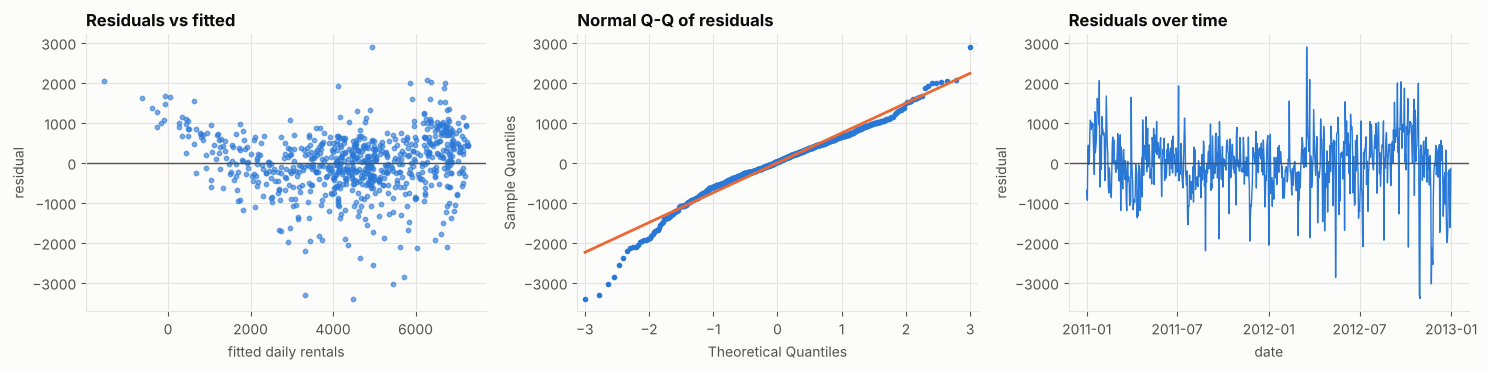

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].scatter(fitted, resid, s=10, color=PALETTE[0], alpha=0.6)
axes[0].axhline(0, color=INK_2, linewidth=1)
axes[0].set(title="Residuals vs fitted", xlabel="fitted daily rentals", ylabel="residual")
sm.qqplot(resid, line="s", ax=axes[1], markersize=3, color=PALETTE[0])
axes[1].get_lines()[1].set_color(PALETTE[1])
axes[1].set(title="Normal Q-Q of residuals")
axes[2].plot(day["dteday"], resid, color=PALETTE[0], linewidth=1)
axes[2].axhline(0, color=INK_2, linewidth=1)
axes[2].set(title="Residuals over time", xlabel="date", ylabel="residual")
axes[2].xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
fig.tight_layout()

All three checks fail, and the plots show why.

- **Not constant variance.** Breusch-Pagan p = 6.38e-10. The residuals also curve (positive at both ends of the fitted range, negative in the middle), which hints that effects are partly multiplicative. A model on log rentals would probably fit better, at the cost of less direct coefficients.
- **Autocorrelated.** Durbin-Watson is 1.210 and the lag-1 autocorrelation is 0.395. If the model under-predicts today, it probably under-predicts tomorrow too.
- **Not normal.** Jarque-Bera p = 1.04e-39, driven by a long left tail of days with far fewer rentals than the weather would suggest. The lowest is 2012-10-29 with 22 rentals, the day Hurricane Sandy reached Washington.

Since the errors are autocorrelated, I refit with Newey-West (HAC) standard errors. The coefficients stay the same. Only the uncertainty around them changes, and it is the honest version.

In [8]:
ols_hac = smf.ols(formula, data=day).fit(cov_type="HAC", cov_kwds={"maxlags": 7})
compare = pd.DataFrame({
    "coef": ols.params,
    "se_ols": ols.bse,
    "se_hac": ols_hac.bse,
    "hac_ci_low": ols_hac.conf_int()[0],
    "hac_ci_high": ols_hac.conf_int()[1],
    "p_hac": ols_hac.pvalues,
})
compare.index = coef.index
compare.round(3)

,coef,se_ols,se_hac,hac_ci_low,hac_ci_high,p_hac
Intercept,5107.304,235.514,310.581,4498.577,5716.031,0.000
weather[T.light rain/snow],-1912.319,189.921,250.864,-2404.003,-1420.635,0.000
weather[T.mist],-424.129,74.424,75.551,-572.206,-276.052,0.000
season[T.fall],1215.335,92.897,157.628,906.389,1524.280,0.000
season[T.spring],877.666,106.350,163.208,557.785,1197.547,0.000
season[T.summer],1068.081,138.701,212.460,651.668,1484.494,0.000
temp_c20,116.135,6.897,11.465,93.664,138.605,0.000
I(temp_c20 ** 2),-7.629,0.648,1.346,-10.267,-4.991,0.000
humidity,-18.814,2.744,3.135,-24.959,-12.670,0.000
windspeed,-50.834,5.904,6.755,-64.073,-37.594,0.000


In [9]:
peak_temp = 20 - ols.params["temp_c20"] / (2 * ols.params["I(temp_c20 ** 2)"])
print(f"temperature where predicted rentals peak: {peak_temp:.1f} C")
print(f"largest se_hac / se_ols ratio: {(compare['se_hac'] / compare['se_ols']).max():.2f}")

temperature where predicted rentals peak: 27.6 C
largest se_hac / se_ols ratio: 2.08


Reading the model, each effect holding the others fixed, with HAC intervals:

- **Year:** 2012 days had 1,941 more rentals than 2011 days (95% CI 1,770 to 2,112). This is the system growing, and it is the biggest single effect.
- **Temperature:** at 20 C each extra degree adds about 116 rentals a day, but the negative squared term bends the curve, and predicted rentals peak at about 27.6 C. Above that it is too hot and rentals start to fall.
- **Weather:** compared with clear days, mist costs 424 rentals and light rain or snow costs 1,912.
- **Humidity and wind:** about 19 fewer rentals per point of humidity and 51 fewer per km/h of wind.
- **Working day:** not significant (HAC p = 0.128), which matches Test 1 in notebook 3. Holidays do lower rentals, by 556, but the HAC p-value is 0.016 instead of 0.001 under plain OLS. The robust standard errors are larger across the board, more than double for the squared temperature term, which is why I would not trust the plain OLS p-values here.

R squared is 0.851. This is a descriptive model of 731 observational days, so the coefficients describe associations, not what would happen if someone changed the weather.

## Part 2. Predicting hourly rentals

### Time-aware validation

Rows are ordered in time, and the goal is to predict the future. A random split would let the model train on, say, December 14 and test on December 13, which leaks information about that week's weather and demand level. So:

- **Test set:** the last three months, October to December 2012. Never touched until the end.
- **Tuning:** `TimeSeriesSplit` on the training period. Each fold trains on an expanding window and validates on the block that comes right after it, so validation is always in the future.

`casual` and `registered` are dropped because they add up to the target.

The weather columns are the weather in that same hour. That makes this a "given the weather, how many rides" model. In production I would feed it a forecast instead, which would add error I am not measuring here.

In [10]:
hour = load_bike_hour().sort_values("timestamp").reset_index(drop=True)
hour["hr_x_workingday"] = hour["hr"].astype(str) + "_" + hour["workingday"].astype(str)
train, test = chronological_split(hour, "timestamp", "2012-10-01")
print(f"train: {train['timestamp'].min()} to {train['timestamp'].max()}  ({len(train):,} hours)")
print(f"test:  {test['timestamp'].min()} to {test['timestamp'].max()}  ({len(test):,} hours)")

cat_features = ["hr", "weekday", "mnth", "season", "weathersit", "hr_x_workingday"]
num_features = ["temp_c", "humidity", "windspeed", "yr", "workingday", "holiday"]
features = cat_features + num_features
X_train, X_test = train[features], test[features]
y_train, y_test = np.log1p(train["cnt"]), test["cnt"].to_numpy()
tscv = TimeSeriesSplit(n_splits=5)

train: 2011-01-01 00:00:00 to 2012-09-30 23:00:00  (15,211 hours)
test:  2012-10-01 00:00:00 to 2012-12-31 23:00:00  (2,168 hours)


I fit everything on `log1p(cnt)` because the counts are skewed and errors scale with the level. Predictions are turned back into counts before scoring, so all metrics below are in rentals per hour.

### Baseline

Any model has to beat something simple. The baseline predicts the training-period average for that hour of day and working-day status.

In [11]:
lookup = train.groupby(["hr", "workingday"])["cnt"].mean()
base_pred = lookup.loc[list(zip(test["hr"], test["workingday"]))].to_numpy()
results = {"baseline (hour x workingday mean)": regression_metrics(y_test, base_pred)}
results

{'baseline (hour x workingday mean)': {'rmse': 119.58926633614539,
  'mae': 79.95043497535264,
  'r2': 0.6480638995428767}}

### Ridge and lasso

Both shrink coefficients to reduce variance. Ridge shrinks them all smoothly. Lasso can set some to exactly zero, so it also selects features. Hour, weekday and month are one-hot encoded, and I include the hour by working-day interaction so the linear models can draw the two daily shapes from notebook 1.

In [12]:
pre_linear = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
    ("num", StandardScaler(), num_features),
])

def tune(model, grid):
    pipe = Pipeline([("pre", pre_linear), ("model", model)])
    search = GridSearchCV(pipe, grid, cv=tscv, scoring="neg_root_mean_squared_error")
    search.fit(X_train, y_train)
    return search

ridge = tune(Ridge(), {"model__alpha": [0.01, 0.1, 1, 10, 100]})
lasso = tune(Lasso(max_iter=20_000), {"model__alpha": [0.0001, 0.0003, 0.001, 0.003, 0.01]})
print("ridge best alpha:", ridge.best_params_["model__alpha"])
print("lasso best alpha:", lasso.best_params_["model__alpha"])

n_coef = lasso.best_estimator_.named_steps["model"].coef_
print(f"lasso kept {np.sum(n_coef != 0)} of {len(n_coef)} coefficients")

for name, search in [("ridge", ridge), ("lasso", lasso)]:
    pred = np.expm1(search.predict(X_test)).clip(min=0)
    results[name] = regression_metrics(y_test, pred)

ridge best alpha: 10
lasso best alpha: 0.001
lasso kept 70 of 105 coefficients


### Gradient boosted trees (LightGBM)

Trees split on raw values, so no one-hot encoding or scaling is needed. They find interactions like hour by working day by temperature on their own. I tune a small grid with the same time-series folds.

In [13]:
lgbm = GridSearchCV(
    LGBMRegressor(n_estimators=600, learning_rate=0.05, subsample=0.8, subsample_freq=1,
                  colsample_bytree=0.8, random_state=SEED, verbose=-1, n_jobs=4),
    {"num_leaves": [15, 31, 63], "min_child_samples": [10, 30]},
    cv=tscv, scoring="neg_root_mean_squared_error",
)
tree_features = ["hr", "weekday", "mnth", "season", "weathersit"] + num_features
lgbm.fit(train[tree_features], y_train)
print("best params:", lgbm.best_params_)
lgbm_pred = np.expm1(lgbm.predict(test[tree_features])).clip(min=0)
results["lightgbm"] = regression_metrics(y_test, lgbm_pred)

best params: {'min_child_samples': 30, 'num_leaves': 15}


### Cross-validated scores on the training period

These are on the log scale (RMSE of log1p counts) and come from the time-series folds only. They are what I used to choose between settings.

In [14]:
cv_table = pd.DataFrame({
    "model": ["ridge", "lasso", "lightgbm"],
    "cv_rmse_log": [-ridge.best_score_, -lasso.best_score_, -lgbm.best_score_],
})
cv_table

,model,cv_rmse_log
0,ridge,0.479775
1,lasso,0.463612
2,lightgbm,0.427883


### Test set results (October to December 2012)

In [15]:
res = pd.DataFrame(results).T[["rmse", "mae", "r2"]]
res

,rmse,mae,r2
baseline (hour x workingday mean),119.589266,79.950435,0.648064
ridge,70.084148,43.404542,0.879130
lasso,70.383942,44.241614,0.878094
lightgbm,66.660229,42.199762,0.890651


LightGBM is best on every metric over the three held-out months: RMSE 66.66 and MAE 42.20 rentals per hour, with R squared 0.891. Ridge and lasso are closer behind than I expected (RMSE 70.08 and 70.38), because the hour by working-day feature hands them the main daily shape. All three cut the baseline RMSE of 119.59 by more than 40%. The time-series CV picked LightGBM too, so the choice made on the training period held up on the future.

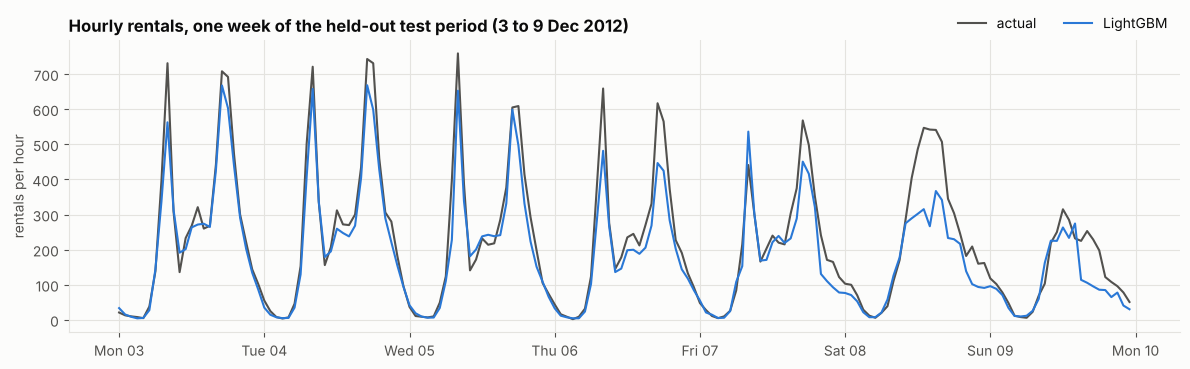

In [16]:
week = test["timestamp"].between("2012-12-03", "2012-12-09 23:00")
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(test.loc[week, "timestamp"], test.loc[week, "cnt"], color=INK_2, linewidth=1.5, label="actual")
ax.plot(test.loc[week, "timestamp"], lgbm_pred[week.to_numpy()], color=PALETTE[0], linewidth=1.5, label="LightGBM")
ax.set(title="Hourly rentals, one week of the held-out test period (3 to 9 Dec 2012)", ylabel="rentals per hour")
ax.legend(loc="upper right", ncol=2, bbox_to_anchor=(1, 1.13))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %d"))
fig.tight_layout()
save(fig, "bike_forecast.png");

### Where the errors are

In [17]:
err = test.assign(pred=lgbm_pred, abs_err=np.abs(test["cnt"] - lgbm_pred))
err.groupby("weather")["abs_err"].agg(["size", "mean"]).rename(columns={"mean": "MAE"})

,size,MAE
weather,,
clear,1224,40.534133
light rain/snow,160,58.656811
mist,784,41.441601


In [18]:
monthly = err.groupby("mnth").apply(lambda g: pd.Series({"actual_mean": g["cnt"].mean(), "pred_mean": g["pred"].mean()}))
monthly

,actual_mean,pred_mean
mnth,,
10,280.848870,252.819941
11,212.623955,187.249076
12,166.729111,159.652709


Two patterns. Errors are biggest in light rain or snow (MAE 58.66 against 40.53 on clear hours), and those hours are rare in training. And the model under-predicts every month on average, most in October (252.82 predicted against 280.85 actual). That is the growth trend. Ridership kept climbing through 2012, and the model only sees growth through the `yr` flag. A trend term, lagged demand, or simply retraining every month would help.

In [19]:
(RESULTS / "regression.json").write_text(json.dumps({
    "train_period": [str(train["timestamp"].min()), str(train["timestamp"].max())],
    "test_period": [str(test["timestamp"].min()), str(test["timestamp"].max())],
    "n_train": len(train), "n_test": len(test),
    "test_metrics": results,
    "ols_daily": {"r2": ols.rsquared, "adj_r2": ols.rsquared_adj, "durbin_watson": dw, "n": int(ols.nobs)},
}, indent=2))
print("saved results/regression.json")

saved results/regression.json
